# PolyPythia 160M seed audit — the data-seed family

Tensor-level audit of what the `EleutherAI/pythia-160m-data-seed{1,2,3}` Hub repos
actually contain, against `EleutherAI/pythia-160m` (the seed-1234 default run).
The model card and PolyPythias Table 5 label them "same init, only data ordering
varied"; this notebook checks both halves of that claim from the released
checkpoints alone (the ablation runs are not in the public W&B project and no
training config is published). Prose SSOT: `docs/POLYPYTHIA_160M_SEED_AUDIT.md`
(§E5, §E7).

Everything is computed live from the fp16 `pytorch_model.bin` files in the HF
cache (`hf_cache_root` in `configs/paths/paths_local.yaml`); ~0.33 GB per
(repo, revision). CPU only, no GPU, no training.

**Run from the repo root:**
```bash
uv sync
uv run jupyter lab notebooks/polypythia_160m_seed_audit.ipynb
```

### Reading guide

- **Two claims, two tests.** *Same init* is tested by exact tensor equality at
  `step0`/`step1` (§1). *Different batch composition* is tested by the
  batch-stream fingerprint (§3–§4): the set of input-embedding rows that move in
  the first two optimizer steps identifies which tokens occurred in the first
  two batches, independently of the init.
- **Calibration before verdict.** Every fingerprint statistic is shown first on a
  pair with a *known* shared stream (`original` vs `weight-seed1`, both on the
  seed-0 index map) and on pairs with *known* distinct streams (`original` vs the
  joint seeds `seed1`, `seed4`). The data-seed pairs are then read against those
  two bands.
- **Divergence alone is not evidence.** §2 shows a same-stream pair diverging
  from `step2` on; only the fingerprint separates "different data" from
  "different run".
- All row-set statistics use real-vocabulary rows `< 50257` (rows 50257–50303
  are padding).

| § | Topic |
|---|---|
| 0 | Inventory — repos, revisions, resolved cache paths |
| 1 | Init identity: `step0 ≡ step1`, and `data-seedN@step1 ≡ original@step1` |
| 2 | Weight divergence from `step2` — necessary, not sufficient |
| 3 | Fingerprint mechanism and per-repo flip statistics |
| 4 | Fingerprint statistics: `J_present`, `J_absent`, symmetric differences |
| 5 | Per-row flip-count correlation — an init-identity confirmation, not a stream test |
| 6 | Verdict (computed) |
| 7 | Limits and how to extend |

### Explicit exclusions

- The weight-seed init-collapse evidence (E1–E6 of the audit doc: `step0` foreign
  copies, `step1` identical to the 1234 init) is not re-derived here;
  `weight-seed1` appears only as the same-stream calibration control.
- No `step0` of any `weight-seed` repo is loaded (mis-uploaded branch).
- Which `pile-preshuffled-seeds/seedN` index map a run used is not identifiable
  from weights and is out of scope.

### Metric cheat-sheet

| ID | Name | Definition |
|---|---|---|
| `n_diff` | tensors differing | count of trainable tensors with `torch.equal(a, b) == False` |
| `relL2` | relative L2 | $\|A-B\|_2 / \|A\|_2$ over concatenated fp32-upcast trainable tensors (buffers excluded) |
| `flips[t]` | per-row flip count | number of elements of `embed_in[t]` whose fp16 value differs between `step1` and `step2` |
| `P` / `A` | present / absent set | `{t : flips[t] > 0}` / `{t : flips[t] == 0}` over real-vocab rows |
| `J_present` | Jaccard on `P` | $|P_a \cap P_b| / |P_a \cup P_b|$ |
| `J_absent` | Jaccard on `A` | $|A_a \cap A_b| / |A_a \cup A_b|$ — the discriminative version |
| `only_a` / `only_b` | symmetric difference | $|P_a \setminus P_b|$, $|P_b \setminus P_a|$ |
| `rho_flips` | Spearman of `flips` | over rows in $P_a \cap P_b$; tracks init identity (see §5) |


## Setup


In [1]:
from __future__ import annotations

import itertools
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from huggingface_hub import hf_hub_download
from huggingface_hub.errors import LocalEntryNotFoundError
from scipy.stats import spearmanr
from transformers import AutoTokenizer

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from subliminal_learning.models.registry import PythiaModelSpec, resolve_hf_repo_id

PATHS = yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())
HF_CACHE_ROOT = Path(PATHS["hf_cache_root"])
HUB_ORG = "EleutherAI"

# label -> (spec, role). Roles drive the calibration bands in §4.
REPOS: dict[str, tuple[PythiaModelSpec, str]] = {
    "original": (PythiaModelSpec("160m", 0, "full"), "reference"),
    "data-seed1": (PythiaModelSpec("160m", 1, "data"), "data-seed"),
    "data-seed2": (PythiaModelSpec("160m", 2, "data"), "data-seed"),
    "data-seed3": (PythiaModelSpec("160m", 3, "data"), "data-seed"),
    "weight-seed1": (PythiaModelSpec("160m", 1, "weight"), "same-stream control"),
    "seed1": (PythiaModelSpec("160m", 1, "full"), "different-stream control"),
    "seed4": (PythiaModelSpec("160m", 4, "full"), "different-stream control"),
}
DATA_FAMILY = ["original", "data-seed1", "data-seed2", "data-seed3"]
REVISIONS = ("step0", "step1", "step2")
NO_STEP0 = {"weight-seed1"}  # mis-uploaded foreign step0; never load

EMBED_KEY = "gpt_neox.embed_in.weight"
REAL_VOCAB = 50257
BUFFERS = ("attention.bias", "attention.masked_bias", "rotary_emb.inv_freq")


def repo_id(label: str) -> str:
    return resolve_hf_repo_id(REPOS[label][0], HUB_ORG)


def state_dict(label: str, revision: str) -> dict[str, torch.Tensor]:
    """fp16 state dict of one Hub revision, buffers dropped."""
    if revision == "step0" and label in NO_STEP0:
        raise ValueError(f"{label}@step0 is a mis-uploaded foreign init; refusing")
    path = hf_hub_download(repo_id(label), "pytorch_model.bin", revision=revision)
    sd = torch.load(path, map_location="cpu", weights_only=True)
    return {k: v for k, v in sd.items() if not k.endswith(BUFFERS)}


def n_diff(a: dict[str, torch.Tensor], b: dict[str, torch.Tensor]) -> int:
    assert a.keys() == b.keys(), "state-dict key sets differ: wrong architecture/repo"
    return sum(not torch.equal(a[k], b[k]) for k in a)


def rel_l2(a: dict[str, torch.Tensor], b: dict[str, torch.Tensor]) -> float:
    num = sum(((a[k].float() - b[k].float()) ** 2).sum().item() for k in a) ** 0.5
    den = sum((a[k].float() ** 2).sum().item() for k in a) ** 0.5
    return num / den


print("hf_cache_root:", HF_CACHE_ROOT)
print("repos        :", {k: repo_id(k) for k in REPOS})


/home/vishesh/eleutherAI/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


hf_cache_root: /mnt/ssd-3/soar-subliminal/vishesh/huggingface
repos        : {'original': 'EleutherAI/pythia-160m', 'data-seed1': 'EleutherAI/pythia-160m-data-seed1', 'data-seed2': 'EleutherAI/pythia-160m-data-seed2', 'data-seed3': 'EleutherAI/pythia-160m-data-seed3', 'weight-seed1': 'EleutherAI/pythia-160m-weight-seed1', 'seed1': 'EleutherAI/pythia-160m-seed1', 'seed4': 'EleutherAI/pythia-160m-seed4'}


## 0. Inventory — repos, revisions, resolved cache paths

Resolves every (repo, revision) this notebook touches. `hf_hub_download` returns
the cached file when present and downloads otherwise (≈0.33 GB each); the table
records which happened so a re-run on another machine is auditable.


In [2]:
rows = []
for label in REPOS:
    for rev in REVISIONS:
        if rev == "step0" and label in NO_STEP0:
            rows.append({"label": label, "revision": rev, "cached": None, "path": "(skipped: foreign step0)"})
            continue
        try:
            p = hf_hub_download(repo_id(label), "pytorch_model.bin", revision=rev, local_files_only=True)
            cached = True
        except LocalEntryNotFoundError:
            p = hf_hub_download(repo_id(label), "pytorch_model.bin", revision=rev)
            cached = False
        rows.append({"label": label, "revision": rev, "cached": cached,
                     "size_MB": round(Path(p).stat().st_size / 1e6, 1),
                     "path": str(Path(p).relative_to(HF_CACHE_ROOT))})
inventory = pd.DataFrame(rows)
print(f"SCOPE inventory: {inventory.path.str.startswith('(skipped').eq(False).sum()} checkpoint files "
      f"across {inventory.label.nunique()} repos x {len(REVISIONS)} revisions")
inventory


SCOPE inventory: 20 checkpoint files across 7 repos x 3 revisions


,label,revision,cached,size_MB,path
0,original,step0,True,375.0,hub/models--EleutherAI--pythia-160m/snapshots/...
1,original,step1,True,375.0,hub/models--EleutherAI--pythia-160m/snapshots/...
2,original,step2,True,375.0,hub/models--EleutherAI--pythia-160m/snapshots/...
3,data-seed1,step0,True,375.0,hub/models--EleutherAI--pythia-160m-data-seed1...
4,data-seed1,step1,True,375.0,hub/models--EleutherAI--pythia-160m-data-seed1...
5,data-seed1,step2,True,375.0,hub/models--EleutherAI--pythia-160m-data-seed1...
6,data-seed2,step0,True,375.0,hub/models--EleutherAI--pythia-160m-data-seed2...
7,data-seed2,step1,True,375.0,hub/models--EleutherAI--pythia-160m-data-seed2...
8,data-seed2,step2,True,375.0,hub/models--EleutherAI--pythia-160m-data-seed2...
9,data-seed3,step0,True,375.0,hub/models--EleutherAI--pythia-160m-data-seed3...


## 1. Init identity — the premise of every stream claim

**What this measures.** Exact per-tensor equality (`torch.equal`, no tolerance) over
the 148 trainable tensors. Two facts are required before any batch-order
statement is meaningful:

1. Within each clean repo, `step0 ≡ step1`. One optimizer step at warmup LR
   (≈4e-7) is below fp16 resolution, so `step1` is the true init at the stored
   precision. This also guards against an off-trajectory `step0` (the
   weight-seed defect).
2. `data-seedN@step1 ≡ original@step1`: the three data-seed runs start from the
   1234 init, bitwise.

Both cells raise if the premise fails.


In [3]:
sd1 = {label: state_dict(label, "step1") for label in REPOS}

rows = []
for label in REPOS:
    if label in NO_STEP0:
        continue
    sd0 = state_dict(label, "step0")
    rows.append({"label": label, "n_tensors": len(sd0), "n_diff(step0,step1)": n_diff(sd0, sd1[label]),
                 "relL2(step0,step1)": rel_l2(sd0, sd1[label])})
on_traj = pd.DataFrame(rows)
print("SCOPE on-trajectory check:", len(on_traj), "repos (weight-seed1 step0 skipped by design)")
display(on_traj)
bad = on_traj[on_traj["n_diff(step0,step1)"] > 0].label.tolist()
assert not bad, f"step0 is off-trajectory for {bad}; do not use their step0"


SCOPE on-trajectory check: 6 repos (weight-seed1 step0 skipped by design)


,label,n_tensors,"n_diff(step0,step1)","relL2(step0,step1)"
0,original,148,0,0.0
1,data-seed1,148,0,0.0
2,data-seed2,148,0,0.0
3,data-seed3,148,0,0.0
4,seed1,148,0,0.0
5,seed4,148,0,0.0


In [4]:
rows = []
for label in REPOS:
    if label == "original":
        continue
    rows.append({"pair": f"original vs {label}", "role": REPOS[label][1],
                 "n_diff@step1": n_diff(sd1["original"], sd1[label]),
                 "relL2@step1": rel_l2(sd1["original"], sd1[label])})
init_identity = pd.DataFrame(rows)
display(init_identity)

same_init = init_identity[init_identity["n_diff@step1"] == 0].pair.str.replace("original vs ", "").tolist()
for label in DATA_FAMILY[1:]:
    assert label in same_init, f"{label} does not share the 1234 init at step1 — card claim fails"
print("PASS: data-seed1/2/3 are tensor-identical to original at step1 (same init).")
print("Different-init controls (relL2 ~1.25 = two independent GPT-NeoX draws):",
      init_identity[init_identity["n_diff@step1"] > 0].pair.tolist())


,pair,role,n_diff@step1,relL2@step1
0,original vs data-seed1,data-seed,0,0.000000
1,original vs data-seed2,data-seed,0,0.000000
2,original vs data-seed3,data-seed,0,0.000000
3,original vs weight-seed1,same-stream control,0,0.000000
4,original vs seed1,different-stream control,50,1.247438
5,original vs seed4,different-stream control,50,1.247518


PASS: data-seed1/2/3 are tensor-identical to original at step1 (same init).
Different-init controls (relL2 ~1.25 = two independent GPT-NeoX draws): ['original vs seed1', 'original vs seed4']


## 2. Weight divergence from `step2` — necessary, not sufficient

**What this measures.** `relL2` between `step1` and `step2` within each repo, and
pairwise `relL2` at `step2` across repos. A different batch stream must produce
divergence by `step2` (the first step whose update survives fp16 rounding). The
converse fails: `weight-seed1` shares both init **and** stream with `original`
(§4 proves the stream part) yet diverges at `step2` too. Divergence therefore
cannot distinguish "different data" from "different run"; §3–§4 can.


In [5]:
sd2 = {label: state_dict(label, "step2") for label in REPOS}

within = pd.DataFrame(
    {"label": label, "role": REPOS[label][1], "relL2(step1,step2)": rel_l2(sd1[label], sd2[label])}
    for label in REPOS
)
display(within)

labels = list(REPOS)
mat = pd.DataFrame(index=labels, columns=labels, dtype=float)
for a, b in itertools.combinations(labels, 2):
    mat.loc[a, b] = mat.loc[b, a] = rel_l2(sd2[a], sd2[b])
for label in labels:
    mat.loc[label, label] = 0.0
print("pairwise relL2 @step2 (same-init pairs ~1e-6; different-init pairs ~1.25):")
display(mat.round(7))


,label,role,"relL2(step1,step2)"
0,original,reference,0.000004
1,data-seed1,data-seed,0.000004
2,data-seed2,data-seed,0.000004
3,data-seed3,data-seed,0.000004
4,weight-seed1,same-stream control,0.000003
5,seed1,different-stream control,0.000004
6,seed4,different-stream control,0.000004


pairwise relL2 @step2 (same-init pairs ~1e-6; different-init pairs ~1.25):


,original,data-seed1,data-seed2,data-seed3,weight-seed1,seed1,seed4
original,0.000000,0.000002,0.000002,0.000002,0.000003,1.247438,1.247518
data-seed1,0.000002,0.000000,0.000002,0.000002,0.000003,1.247438,1.247518
data-seed2,0.000002,0.000002,0.000000,0.000002,0.000003,1.247438,1.247518
data-seed3,0.000002,0.000002,0.000002,0.000000,0.000003,1.247438,1.247518
weight-seed1,0.000003,0.000003,0.000003,0.000003,0.000000,1.247438,1.247518
seed1,1.247438,1.247438,1.247438,1.247438,1.247438,0.000000,1.247526
seed4,1.247518,1.247518,1.247518,1.247518,1.247518,1.247526,0.000000


## 3. Fingerprint mechanism and per-repo flip statistics

**Mechanism.** Pythia is trained with untied embeddings (`no-weight-tying: true`),
so row `t` of `gpt_neox.embed_in.weight` (50 304 × 768) enters the forward pass only
when token `t` occurs in the batch. A row whose token is absent from a batch has an
exactly-zero gradient, zero Adam moments, and does not move (decoupled weight decay
at lr ≈ 8e-7 is ~1e-10, far below fp16 resolution). After the first two optimizer
steps, **the set of rows that changed = the set of tokens present in batches 0–1**,
a property of the data stream and not of the init.

**Why `step1 → step2`.** Checkpoints are fp16 snapshots of fp32 master weights.
The step-2 Adam update (≈lr ≈ 8e-7 per element) only crosses an fp16 rounding
boundary for small-magnitude elements (|w| ≲ 1e-3), i.e. a few percent of each
row. A row has 768 elements, so a touched row still shows many flipped elements
(median ≈ 18). The cell below checks the low tail (1st percentile of flips per
touched row ≥ 5, and counts rows with ≤ 2 flips): a gradient-receiving row that
shows *zero* flips would be misclassified as absent, and the tail size bounds how
many such rows there can be — a handful at most, against the ~900 discordant
rows a different stream produces (§4). Later windows are contaminated by
delayed flips of rows touched earlier, so only the first window is used.

**What this measures.** Per repo: rows touched, rows absent, flip-count
distribution over touched rows, and the identity of untouched tokens (expected:
padding, byte-fallback bytes, rare BPE pieces).


In [6]:
flips: dict[str, np.ndarray] = {}
for label in REPOS:
    e1 = sd1[label][EMBED_KEY].float()
    e2 = sd2[label][EMBED_KEY].float()
    assert e1.shape == (50304, 768), e1.shape
    flips[label] = (e1 != e2).sum(dim=1).numpy()[:REAL_VOCAB]

tok = AutoTokenizer.from_pretrained(repo_id("original"))
rows = []
for label, f in flips.items():
    touched = f[f > 0]
    absent_ids = np.flatnonzero(f == 0)
    rows.append({"label": label, "role": REPOS[label][1],
                 "rows_touched": int((f > 0).sum()), "rows_absent": int((f == 0).sum()),
                 "min_flips": int(touched.min()), "rows_le2_flips": int((touched <= 2).sum()),
                 "p1_flips": float(np.percentile(touched, 1)), "median_flips": float(np.median(touched)),
                 "max_flips": int(touched.max()),
                 "absent_sample": [tok.decode([int(i)]) for i in absent_ids[::max(1, len(absent_ids) // 6)][:6]]})
flip_stats = pd.DataFrame(rows)
print(f"SCOPE fingerprint window step1->step2, real-vocab rows < {REAL_VOCAB}, {len(flip_stats)} repos")
display(flip_stats)
assert (flip_stats.p1_flips >= 5).all(), "low-flip tail too heavy: row-level presence unreliable"
assert (flip_stats.rows_le2_flips <= 10).all(), "too many barely-touched rows: misclassification risk"


SCOPE fingerprint window step1->step2, real-vocab rows < 50257, 7 repos


,label,role,rows_touched,rows_absent,min_flips,rows_le2_flips,p1_flips,median_flips,max_flips,absent_sample
0,original,reference,48603,1654,2,3,7.0,18.0,44,"[<|padding|>, ylvania, opio, \n , olor, ి]"
1,data-seed1,data-seed,48511,1746,1,4,7.0,18.0,43,"[<|padding|>, ¸, Austral, benefici, visiae, H..."
2,data-seed2,data-seed,48546,1711,2,2,7.0,18.0,42,"[<|padding|>, arijuana, Lear, ്, Wheat, cket]"
3,data-seed3,data-seed,48578,1679,1,2,7.0,18.0,44,"[<|padding|>, ─, careg, benefici, omez, CTR]"
4,weight-seed1,same-stream control,48602,1655,2,4,7.0,17.0,37,"[<|padding|>, ylvania, opio, \n , olor, ి]"
5,seed1,different-stream control,48603,1654,2,1,7.0,18.0,41,"[<|padding|>, swit, insula, deze, LONG, pts]"
6,seed4,different-stream control,48568,1689,2,2,7.0,18.0,42,"[<|padding|>, ––, lemental, HEP, pués, UFO]"


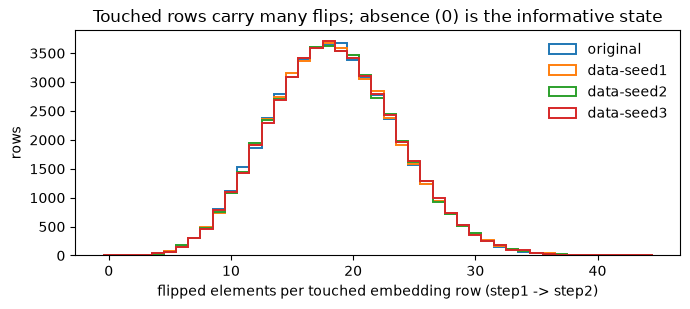

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.arange(0, flip_stats.max_flips.max() + 2) - 0.5
for label in DATA_FAMILY:
    f = flips[label]
    ax.hist(f[f > 0], bins=bins, histtype="step", lw=1.4, label=label)
ax.set_xlabel("flipped elements per touched embedding row (step1 -> step2)")
ax.set_ylabel("rows")
ax.set_title("Touched rows carry many flips; absence (0) is the informative state")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


## 4. Fingerprint statistics — do the data-seed streams differ?

**What this measures.** For every pair of repos, the Jaccard overlap of the
present-row sets (`J_present`), of the absent-row sets (`J_absent`), and the two
one-sided differences `only_a = |P_a \ P_b|`, `only_b = |P_b \ P_a|`.

**How to read it.**
- `J_present ≈ 0.96` is a floor effect: any two ~4M-token Pile samples share the
  same ~48.5k common tokens, so the union is dominated by a shared core and
  Jaccard is compressed toward 1. The information is in the symmetric
  difference (tokens that occur in one run's first two batches but not the
  other's).
- `J_absent` restricts to the ~1.7k rare tokens absent from each run's first two
  batches. Two runs on the same stream must agree exactly (≈1.0); independent
  samples of rare tokens overlap by only ~30%. This is the discriminative
  statistic.
- The `same-stream control` row (`original` vs `weight-seed1`) fixes the
  false-positive rate: those runs have an unlogged systematic difference (their
  step-2 update is ~21% smaller in full-model `relL2`, §2) yet must show ~0
  discordant rows, because
  row presence is binary in token occurrence. The `different-stream control`
  rows (`original` vs `seed1`/`seed4`, documented distinct index maps) fix the
  different-stream band. Data-seed pairs are read against both.


In [8]:
def jaccard(a: set[int], b: set[int]) -> float:
    return len(a & b) / len(a | b)


JOINT = {k for k, (_, role) in REPOS.items() if role == "different-stream control"}


def pair_kind(a: str, b: str) -> str:
    """Calibration class: documented same stream, documented distinct streams, or under test."""
    s = {a, b}
    if s <= set(DATA_FAMILY):
        return "data-seed pair"
    if s == {"original", "weight-seed1"}:
        return "same-stream control"
    if s <= JOINT | {"original"}:
        return "different-stream control"
    return "other"


present = {k: set(np.flatnonzero(f > 0)) for k, f in flips.items()}
absent = {k: set(np.flatnonzero(f == 0)) for k, f in flips.items()}

rows = []
for a, b in itertools.combinations(REPOS, 2):
    both = (flips[a] > 0) & (flips[b] > 0)
    rows.append({"a": a, "b": b, "kind": pair_kind(a, b),
                 "J_present": jaccard(present[a], present[b]),
                 "J_absent": jaccard(absent[a], absent[b]),
                 "only_a": len(present[a] - present[b]), "only_b": len(present[b] - present[a]),
                 "rho_flips": spearmanr(flips[a][both], flips[b][both]).statistic})
pairs = pd.DataFrame(rows)
order = ["same-stream control", "different-stream control", "data-seed pair", "other"]
pairs["kind"] = pd.Categorical(pairs["kind"], order, ordered=True)
pairs = pairs.sort_values(["kind", "a", "b"]).reset_index(drop=True)
print(f"SCOPE pairs: {len(pairs)} ({pairs.kind.value_counts().to_dict()})")
display(pairs.style.format({"J_present": "{:.4f}", "J_absent": "{:.3f}", "rho_flips": "{:.3f}"}))


SCOPE pairs: 21 ({'other': 11, 'data-seed pair': 6, 'different-stream control': 3, 'same-stream control': 1})


,a,b,kind,J_present,J_absent,only_a,only_b,rho_flips
0,original,weight-seed1,same-stream control,1.0000,0.999,1,0,0.761
1,original,seed1,different-stream control,0.9638,0.297,896,896,0.191
2,original,seed4,different-stream control,0.9632,0.295,927,892,0.188
3,seed1,seed4,different-stream control,0.9646,0.313,892,857,0.199
4,data-seed1,data-seed2,data-seed pair,0.9611,0.285,945,980,0.683
5,data-seed1,data-seed3,data-seed pair,0.9636,0.311,867,934,0.679
6,data-seed2,data-seed3,data-seed pair,0.9627,0.295,907,939,0.679
7,original,data-seed1,data-seed pair,0.9633,0.304,953,861,0.675
8,original,data-seed2,data-seed pair,0.9621,0.284,966,909,0.677
9,original,data-seed3,data-seed pair,0.9639,0.302,905,880,0.679


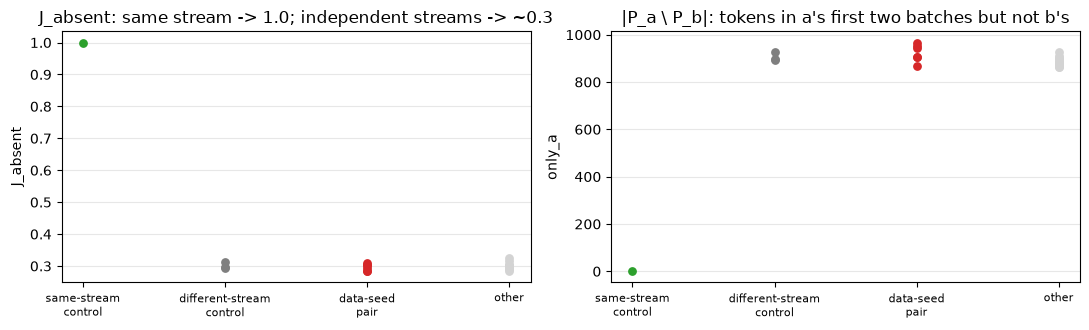

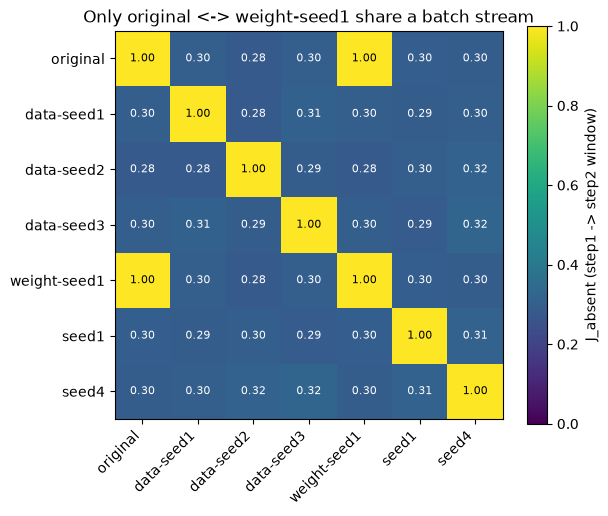

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
colors = {"same-stream control": "tab:green", "different-stream control": "tab:gray",
          "data-seed pair": "tab:red", "other": "lightgray"}
for ax, col in zip(axes, ["J_absent", "only_a"]):
    for i, kind in enumerate(order):
        sub = pairs[pairs.kind == kind]
        ax.scatter([i] * len(sub), sub[col], color=colors[kind], s=28, zorder=3)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([k.replace(" ", "\n") for k in order], fontsize=8)
    ax.set_ylabel(col)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_title("J_absent: same stream -> 1.0; independent streams -> ~0.3")
axes[1].set_title("|P_a \\ P_b|: tokens in a's first two batches but not b's")
plt.tight_layout()
plt.show()

heat = pd.DataFrame(index=list(REPOS), columns=list(REPOS), dtype=float)
for r in pairs.itertuples():
    heat.loc[r.a, r.b] = heat.loc[r.b, r.a] = r.J_absent
for label in REPOS:
    heat.loc[label, label] = 1.0
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(heat.values.astype(float), vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(heat))); ax.set_xticklabels(heat.columns, rotation=45, ha="right")
ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index)
for i in range(len(heat)):
    for j in range(len(heat)):
        ax.text(j, i, f"{heat.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if heat.values[i, j] < 0.6 else "black")
plt.colorbar(im, ax=ax, label="J_absent (step1 -> step2 window)")
ax.set_title("Only original <-> weight-seed1 share a batch stream")
plt.tight_layout()
plt.show()


## 5. Per-row flip-count correlation — an init-identity confirmation, not a stream test

**What this measures.** Spearman correlation of `flips[t]` between two repos over
rows touched in both. How many of a row's 768 elements cross an fp16 boundary
depends on how many of that row's *init values* sit near a rounding boundary, so
`rho_flips` tracks whether the two runs share an init — it is **confounded** for
the stream question and is shown here only so it is not mistaken for one.
Expected: same-init pairs high regardless of stream; different-init pairs low.


In [10]:
def init_kind(a: str, b: str) -> str:
    return "different init" if (a in JOINT or b in JOINT) else "same init"


pairs["init"] = [init_kind(a, b) for a, b in zip(pairs.a, pairs.b)]
summary = pairs.groupby(["init", "kind"], observed=True).rho_flips.agg(["mean", "min", "max", "count"]).round(3)
display(summary)
ds_rho = pairs[(pairs.kind == "data-seed pair")].rho_flips
ctrl_rho = pairs[pairs.init == "different init"].rho_flips
print(f"data-seed pairs rho_flips {ds_rho.min():.3f}-{ds_rho.max():.3f} (same init) vs "
      f"different-init pairs {ctrl_rho.min():.3f}-{ctrl_rho.max():.3f}: consistent with §1, silent on stream.")


mean    min    max  count
init           kind                                                
different init different-stream control  0.193  0.188  0.199      3
               other                     0.166  0.099  0.196      8
same init      same-stream control       0.761  0.761  0.761      1
               data-seed pair            0.679  0.675  0.683      6
               other                     0.619  0.617  0.620      3

data-seed pairs rho_flips 0.675-0.683 (same init) vs different-init pairs 0.099-0.199: consistent with §1, silent on stream.


## 6. Verdict (computed)

Pass criteria, fixed before reading the data-seed rows:

| check | criterion |
|---|---|
| same-stream control sane | `J_absent > 0.99` and `only_a + only_b ≤ 2` for `original` vs `weight-seed1` |
| different-stream band | every `different-stream control` pair has `J_absent < 0.5` |
| data-seed vs original | each `data-seedN` vs `original`: `J_absent < 0.5`, `only_a + only_b > 500` |
| data-seeds mutually distinct | each `data-seedI` vs `data-seedJ`: same thresholds |
| same init (from §1) | `n_diff@step1 == 0` for each `data-seedN` vs `original` |

The cell raises on any failure; the printed lines are the source of truth for
the audit doc's E7 table.


In [11]:
ctrl_same = pairs[pairs.kind == "same-stream control"].iloc[0]
assert ctrl_same.J_absent > 0.99 and (ctrl_same.only_a + ctrl_same.only_b) <= 2, ctrl_same
ctrl_diff = pairs[pairs.kind == "different-stream control"]
assert (ctrl_diff.J_absent < 0.5).all(), ctrl_diff

ds = pairs[pairs.kind == "data-seed pair"].copy()
ds["distinct_stream"] = (ds.J_absent < 0.5) & ((ds.only_a + ds.only_b) > 500)
assert ds.distinct_stream.all(), ds[~ds.distinct_stream]

print("same-stream control  original vs weight-seed1 : "
      f"J_present={ctrl_same.J_present:.4f} J_absent={ctrl_same.J_absent:.3f} "
      f"discordant rows={int(ctrl_same.only_a + ctrl_same.only_b)}")
print("different-stream band (joint seeds)          : "
      f"J_present {ctrl_diff.J_present.min():.4f}-{ctrl_diff.J_present.max():.4f}, "
      f"J_absent {ctrl_diff.J_absent.min():.3f}-{ctrl_diff.J_absent.max():.3f}, "
      f"only_a {int(ctrl_diff.only_a.min())}-{int(ctrl_diff.only_a.max())}")
print("data-seed family (6 pairs incl. original)    : "
      f"J_present {ds.J_present.min():.4f}-{ds.J_present.max():.4f}, "
      f"J_absent {ds.J_absent.min():.3f}-{ds.J_absent.max():.3f}, "
      f"only_a {int(ds.only_a.min())}-{int(ds.only_a.max())}, only_b {int(ds.only_b.min())}-{int(ds.only_b.max())}")
print()
print("VERDICT: original + data-seed{1,2,3} share the 1234 init bitwise (§1) and run on four")
print("         pairwise-distinct batch streams from batch 0 (§4). The data-seed family is a")
print("         valid same-init / different-batch-composition ablation, as the card claims.")


same-stream control  original vs weight-seed1 : J_present=1.0000 J_absent=0.999 discordant rows=1
different-stream band (joint seeds)          : J_present 0.9632-0.9646, J_absent 0.295-0.313, only_a 892-927
data-seed family (6 pairs incl. original)    : J_present 0.9611-0.9639, J_absent 0.284-0.311, only_a 867-966, only_b 861-980

VERDICT: original + data-seed{1,2,3} share the 1234 init bitwise (§1) and run on four
         pairwise-distinct batch streams from batch 0 (§4). The data-seed family is a
         valid same-init / different-batch-composition ablation, as the card claims.


## 7. Limits and how to extend

**Limits.**
- The fingerprint covers the first two batches (~4M tokens). It shows the streams
  differ *from the start*; that they differ at every later step is the only
  plausible reading for shuffled index maps, but it is an inference, not a
  measurement.
- It cannot say *which* `pile-preshuffled-seeds/seedN` map a run used; that
  would require the tokenized Pile itself.
- It relies on fp16 snapshots exposing many flips per touched row (1st percentile
  ≥ 5, asserted in §3); re-check that tail before reusing the method at another
  model size, LR, or checkpoint precision.
- `rho_flips` (§5) is init-confounded; do not report it as a stream statistic.

**How to extend.**
- Add a repo: one entry in `REPOS` with its `PythiaModelSpec` and a role; every
  table and plot picks it up. Put the wrong label in `NO_STEP0` if its `step0`
  is known to be off-trajectory.
- Add the retrained `weight-seed` repos when EleutherAI publishes them: they
  should land at `J_absent ≈ 1.0` vs `original` (same stream) while §1 shows
  `n_diff@step1 = 148` and `relL2@step1 ≈ 1.25` (fresh init).
- `REAL_VOCAB`, `EMBED_KEY`, `BUFFERS` are the only model-specific constants.
